# Module 3 — Confounding & Regression Adjustment

Part of the Causal Inference Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The running question: did NSW (National Supported Work), a US job-training program for men with very low earnings, raise the earnings of the men who took it?
- The men who took the program are called the treated men. Each man also has "before" columns: facts about him from before the program, such as his age, his education and his earlier earnings. The outcome is his earnings after the program.
- The treated men were different from the men they're compared with, even before the program started. Traits that affect both who took the program and earnings afterwards are confounders, and the comparison has to adjust for them. The data has columns for some of them, not all.
- Splitting the men into groups that share the same values, and comparing inside each group, runs out of men after a few columns.
- Module 3 uses regression instead: a formula that predicts what each treated man would have earned without the program, from all the "before" columns at once.
- What can go wrong: the formula's shape is the analyst's choice, and where no comparison man looks like a treated man, the formula still answers, with a guess.

**What this module produces:**
1. A small made-up example, worked by hand: the regression steps, and what happens when the formula guesses beyond the data.
2. A regression estimate of the program's effect on the real data, using every "before" column, with its uncertainty.
3. A check of how much that estimate depends on the formula's shape, and a way to test each shape against the data.

## From the curriculum

> ## <u>Module 3 — Confounding & Regression Adjustment</u>
>
> **Concepts**
> - Regression: a formula, fitted to data, that predicts one column (1978
>   earnings) from other columns. Each column gets a coefficient: how much the
>   prediction moves when that column goes up by 1 and the others stay the same.
> - Regression adjustment for the ATT (average treatment effect on the
>   treated), in three steps:
>   1. Fit the formula on the comparison men only, who never took the program.
>   2. Use it to predict each treated man's 1978 earnings without the program.
>   3. The effect estimate is the mean of (actual with the program − predicted without it) over the treated men.
> - The common shortcut: one regression on all men, with "took the program"
>   as one more column.
> - What regression assumes: every confounder has a column, and the formula's
>   shape is right.
> - Extrapolation: where no comparison man looks like a treated man, the
>   formula still gives a prediction, by continuing its shape past the data.
>   Nothing in the data checks that guess.
>
> **Why it matters**
> Splitting men into groups runs out of men after a few columns. Regression
> uses every column at once, which is why it's the default tool. But it always
> returns a number, even where the groups don't overlap, so the analyst has to
> check where its answer comes from.
>
> **Worked example**
> 1. Seven men on made-up numbers: the three steps by hand, and how the answer
>    changes when the formula's guess beyond the data is wrong.
> 2. NSW (National Supported Work) job-training data vs the PSID (Panel Study
>    of Income Dynamics) men: regression adjustment with all 8 "before"
>    columns, with a 95% confidence interval.
> 3. The same 8 columns in four reasonable formula shapes, a check of each
>    shape on the PSID men who look most like the treated men, and a direct
>    test on the men kept out by the lottery.
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 5 "Unconfoundedness"](https://mixtape.scunning.com/05-causal_cross_sectional_designs)
>   (Scott Cunningham, ~45 min for sections 5.9–5.10, verified): regression
>   adjustment, and the same NSW data.
> - [The Effect, ch. 13 "Regression"](https://theeffectbook.net/ch-StatisticalAdjustment.html)
>   (Nick Huntington-Klein, ~60 min, verified): what a coefficient means, and
>   adjusting for columns with regression.
>
> **Exercise type:** redo the regression adjustment with the CPS (Current
> Population Survey, a monthly US labour survey) comparison group, in two
> shapes, and check each shape. Fully worked.
>
> **Interview angle:** "Our regression says users with feature X are 5 points
> more likely to keep using the app, with controls. Is that the effect of X?"

## Lesson

### What regression is

Regression fits a formula that predicts one column from other columns. Here, it predicts 1978 earnings from the "before" columns, for example:

predicted 1978 earnings = (starting point) + (coefficient of 1975 earnings × 1975 earnings) + (coefficient of education × years of education) + ...

- Each column gets a coefficient: how much the prediction moves when that column goes up by 1 and every other column stays the same.
- "Every other column stays the same" is what makes regression an adjustment: each coefficient is read as a change between men who are alike on the other columns, like comparing inside groups, but without needing exact matches.
- The software picks the coefficients that make the predictions miss the real values by as little as possible. The usual rule is least squares: the smallest sum of squared misses.

### Regression adjustment for the effect on the treated men

The question is about the treated men: the ATT (average treatment effect on the treated) is how much the program changed their 1978 earnings, on average.

Regression adjustment estimates it in three steps:
1. Fit the formula on the comparison men only. They never took the program, so their formula shows how earnings behave without it.
2. Use that formula to predict each treated man's 1978 earnings without the program, from his own "before" columns.
3. ATT estimate = the mean of (actual 1978 earnings with the program − predicted 1978 earnings without the program), over the treated men.

### What it assumes

1. Every confounder has a column in the data. A confounder with no column (motivation, for example) isn't in the formula, so it can't be adjusted for.
2. The formula's shape is right: for example, a straight line in 1975 earnings, rather than a curve.
3. The comparison men cover the treated men's values. Where they don't, the formula extrapolates: it continues its shape past the last comparison man, and nothing in the data checks that guess.

## Worked example 1: the three steps by hand, on made-up numbers

**Chosen example** (not data), because only made-up numbers have a known true effect to check against. Every number is chosen. Earnings are in $ thousands.

**The setup:** 7 men. 4 comparison men never took the program, and 3 treated men took it.
- Without the program, every man would earn: 1978 earnings = 1 + (0.5 × 1975 earnings).

| Man | Took the program? | 1975 earnings | 1978 earnings |
|---|---|---|---|
| comparison man 1 | no | 2 | 2 |
| comparison man 2 | no | 4 | 3 |
| comparison man 3 | no | 6 | 4 |
| comparison man 4 | no | 8 | 5 |
| man A | yes | 0 | 3 |
| man B | yes | 0 | 2 |
| man C | yes | 2 | 4 |

- So the true effects are: man A = 3 − 1 = 2, man B = 2 − 1 = 1, man C = 4 − 2 = 2. True ATT = (2 + 1 + 2) / 3 = 1.67.

**The motive:** the treated men earned less before the program, so a plain comparison should miss the true 1.67. Comparing inside groups can't help either: no comparison man earned 0 in 1975, so men A and B have nobody to be compared with. Regression should still find 1.67.

**Naive gap** = (mean 1978 earnings of the treated men, 3 men) − (mean 1978 earnings of the comparison men, 4 men)

Why: this is the comparison anyone would make first. It should miss the true 1.67.

- Naive gap = ((3 + 2 + 4) / 3) − ((2 + 3 + 4 + 5) / 4) = 3 − 3.5 = −0.5

**Step 1 of 3: the formula**, fitted on the comparison men only

Why: the comparison men show how 1978 earnings follow 1975 earnings without the program.

The software fits the formula and returns: predicted 1978 earnings without the program = 1 + (0.5 × 1975 earnings).
- In words: a man who earned 0 in 1975 is predicted to earn 1 in 1978, and each extra 1 of 1975 earnings adds 0.5.
- It's the same formula as in the setup, because the 4 comparison men were built from it.

**Step 2 of 3: each treated man's predicted 1978 earnings without the program**

Why: this is the missing number for each treated man: what he would have earned without the program.

- Man A = 1 + (0.5 × 0) = 1
- Man B = 1 + (0.5 × 0) = 1
- Man C = 1 + (0.5 × 2) = 2

**Step 3 of 3: ATT estimate** = the mean of (actual − predicted), over the treated men (3 men)

Why: each man's (actual − predicted) is his estimated effect, and the ATT is their mean.

- Man A = 3 − 1 = 2, man B = 2 − 1 = 1, man C = 4 − 2 = 2
- ATT estimate = (2 + 1 + 2) / 3 = 1.67

**Observation:** the naive gap is (−0.5): the program looks harmful. Regression adjustment gives 1.67, the true ATT.

**The catch:** men A and B earned 0 in 1975, below the lowest comparison man (2). Their predictions come from continuing the line past the data: that's extrapolation. In this example the line also holds below 2, because the numbers were chosen that way. Real data gives no such promise.

**What if men with no 1975 earnings didn't sit on the line?** Only one thing changes: what men A and B would have earned without the program.

| | 1975 earnings | 1978 earnings without the program: before | now |
|---|---|---|---|
| man A | 0 | 1 | **2** |
| man B | 0 | 1 | **2** |
| man C | 2 | 2 | 2 |
| the 4 comparison men | 2, 4, 6, 8 | 2, 3, 4, 5 | 2, 3, 4, 5 |

- The true effects changed: man A = 3 − 2 = 1, man B = 2 − 2 = 0, man C = 4 − 2 = 2.
- True ATT = (mean of the true effects, over the treated men, 3 men) = (1 + 0 + 2) / 3 = 1, down from 1.67.
- Regression's estimate stays 1.67: the comparison men, all it sees, didn't change.
- Why it matters: where treated men have no comparison men like them, regression can be wrong with nothing in the data to warn you.

The chart shows the 7 men, the fitted line (dashed where it's continued past the comparison men), and each treated man's estimated effect.

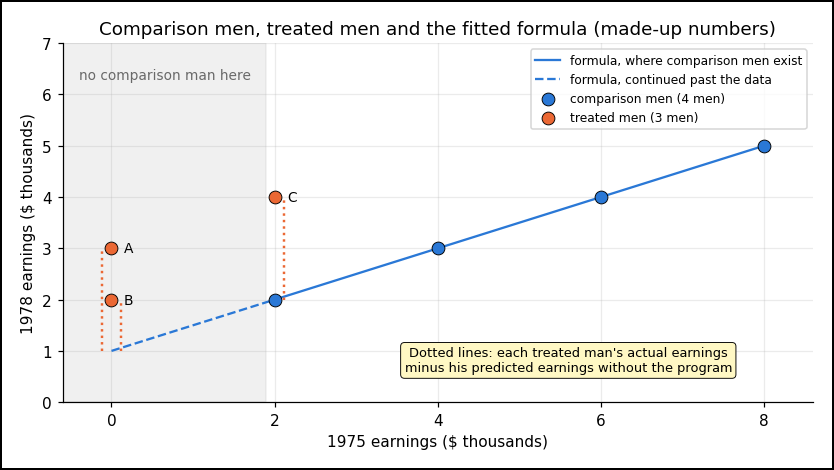

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

import common
from common import show, BLUE, ORANGE, GREY

GREEN, RED = "#1a7f37", "#cf222e"
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot([2, 8], [2, 5], color=BLUE, lw=1.5, label="formula, where comparison men exist")
ax.plot([0, 2], [1, 2], color=BLUE, lw=1.5, ls="--", label="formula, continued past the data")
ax.scatter([2, 4, 6, 8], [2, 3, 4, 5], s=70, color=BLUE, ec="black", lw=0.6, zorder=3, label="comparison men (4 men)")
ax.scatter([0, 0, 2], [3, 2, 4], s=70, color=ORANGE, ec="black", lw=0.6, zorder=3, label="treated men (3 men)")
for x, y, name in [(0, 3, "A"), (0, 2, "B"), (2, 4, "C")]:
    ax.annotate(name, (x, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
# Each treated man's estimated effect: from his predicted earnings without the program (on the line) up to his actual earnings.
for x, y, dx in [(0, 3, -0.12), (0, 2, 0.12), (2, 4, 0.12)]:
    ax.plot([x + dx, x + dx], [1 + 0.5 * x, y], color=ORANGE, lw=1.6, ls=":")
ax.text(5.6, 0.6, "Dotted lines: each treated man's actual earnings\nminus his predicted earnings without the program",
        ha="center", fontsize=8.5, bbox=dict(boxstyle="round", fc="#fff8c4", ec="black", lw=0.6))
ax.axvspan(-0.6, 1.9, color=GREY, alpha=0.12)
ax.text(0.65, 6.3, "no comparison man here", ha="center", fontsize=9, color="dimgray")
ax.set_xlim(-0.6, 8.6)
ax.set_ylim(0, 7)
ax.set_xlabel("1975 earnings ($ thousands)")
ax.set_ylabel("1978 earnings ($ thousands)")
ax.set_title("Comparison men, treated men and the fitted formula (made-up numbers)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion (on made-up data with a known truth):**
- Regression adjustment found the true effect where the plain comparison got the sign wrong, and where comparing inside groups had nobody to compare with.
- For men A and B, the answer rests on the line's shape outside the data. Regression returns a number either way, so the analyst has to check where the treated men sit.

## Worked example 2: regression adjustment on the real data

**The data, again:** the 185 treated men took NSW in 1976 or 1977. They're compared with 2,490 men from the PSID (Panel Study of Income Dynamics), a US household survey of men who never applied to the program. Each man has 8 "before" columns: age, years of education, black, hispanic, married, no degree, 1974 earnings and 1975 earnings.

The same data also has a lottery experiment: 260 men who applied but were kept out by a lottery. Comparing them with the treated men gives an effect of $1,794.3. That's the benchmark: an estimate with its own uncertainty, but free of selection bias (the part of a gap that comes from the groups being different to begin with). Every estimate below is compared with it.

**The motive:** the naive gap, the plain comparison of the treated men with the PSID men, compares men who earned very little before the program with men who mostly earned a lot. Regression adjustment with all 8 "before" columns should move it much closer to the benchmark.

### Step 1 of 3: the formula, fitted on the PSID men only

In [2]:
exp = common.load_lalonde("experimental")
psid = common.load_lalonde("psid")
nsw_t = exp[exp.treat == 1].copy()
psid_c = psid[psid.treat == 0].copy()
benchmark = common.BENCHMARK_ATT
COLS8 = ["age", "education", "black", "hispanic", "married", "nodegree", "re74", "re75"]
LINEAR = "re78 ~ " + " + ".join(COLS8)

naive = nsw_t.re78.mean() - psid_c.re78.mean()
print(f"Naive gap = (mean 1978 earnings of the treated men, {len(nsw_t)} men) - (mean 1978 earnings of the PSID men, {len(psid_c):,} men) = "
      f"{nsw_t.re78.mean():,.1f} - {psid_c.re78.mean():,.1f} = {naive:,.1f}")
print()
fit = smf.ols(LINEAR, psid_c).fit()
meaning = {
    "Intercept": "the formula's starting point, where every column is 0. No man is aged 0, so on its own it means nothing",
    "age": "each extra year of age",
    "education": "each extra year of education",
    "black": "being black, vs not",
    "hispanic": "being hispanic, vs not",
    "married": "being married, vs not",
    "nodegree": "having no high-school degree, vs having one",
    "re74": "each extra $1 of 1974 earnings",
    "re75": "each extra $1 of 1975 earnings",
}
names = {"Intercept": "starting point", "age": "age", "education": "years of education", "black": "black", "hispanic": "hispanic",
         "married": "married", "nodegree": "no degree", "re74": "1974 earnings", "re75": "1975 earnings"}
show(pd.DataFrame({
    "column": [names[k] for k in fit.params.index],
    f"coefficient, fitted on the PSID men ({int(fit.nobs):,} men)": [f"{v:,.3f}" for v in fit.params],
    "the coefficient is the change in predicted 1978 earnings for": [meaning[k] for k in fit.params.index],
}))

Naive gap = (mean 1978 earnings of the treated men, 185 men) - (mean 1978 earnings of the PSID men, 2,490 men) = 6,349.1 - 21,553.9 = -15,204.8

column              coefficient, fitted on the PSID men (2,490 men)  the coefficient is the change in predicted 1978 earnings for
starting point                                             -120.220  the formula's starting point, where every column is 0. No man is aged 0, so on its own it means nothing
age                                                         -93.569  each extra year of age
years of education                                          594.866  each extra year of education
black                                                      -570.695  being black, vs not
hispanic                                                  2,502.686  being hispanic, vs not
married                                                   1,380.750  being married, vs not
no degree                                                   768.542  having no high-school

**How to read a row:** the coefficient of years of education is 594.866. Among PSID men alike on the other 7 columns, each extra year of education goes with about $594.9 more predicted 1978 earnings. The coefficient of 1975 earnings is 0.567: each extra $1 earned in 1975 goes with $0.567 more in 1978.

These are links in the PSID men's data, not effects: the formula is used only to predict, so no coefficient needs a causal meaning.

### Step 2 of 3: predict each treated man's earnings without the program

### Step 3 of 3: compare each treated man's actual earnings with his predicted earnings

In [3]:
def regression_att(formula, comparison, treated):
    """Regression adjustment: fit on the comparison men, predict the treated men without the program, return the mean predicted and the ATT."""
    model = smf.ols(formula, comparison).fit()
    predicted = model.predict(treated)
    return predicted.mean(), (treated.re78 - predicted).mean(), model

pred_mean, att_reg, _ = regression_att(LINEAR, psid_c, nsw_t)
print(f"Mean predicted 1978 earnings without the program, treated men ({len(nsw_t)} men) = {pred_mean:,.1f}")
print()
print(f"ATT estimate = (mean actual 1978 earnings, treated men, {len(nsw_t)} men) - (mean predicted 1978 earnings without the program, treated men, {len(nsw_t)} men) = "
      f"{nsw_t.re78.mean():,.1f} - {pred_mean:,.1f} = {att_reg:,.1f}")

Mean predicted 1978 earnings without the program, treated men (185 men) = 5,558.6

ATT estimate = (mean actual 1978 earnings, treated men, 185 men) - (mean predicted 1978 earnings without the program, treated men, 185 men) = 6,349.1 - 5,558.6 = 790.5


**Observation:** regression adjustment moves the estimate from (−$15,204.8) to $790.5. The sign now matches the benchmark's: positive. It's still $1,003.8 below the benchmark, $1,794.3.

### How sure is $790.5?

Like any estimate from a sample, $790.5 would come out different on another sample of men. The 95% confidence interval measures by how much. Here it's found by the bootstrap, which works for any calculation, however many steps it has:
1. Draw a new sample from the data: 185 treated men and 2,490 PSID men, drawn at random with replacement (the same man can be drawn more than once).
2. Redo all three steps on it.
3. Repeat 1,000 times. The middle 95% of the 1,000 estimates is the 95% confidence interval.

In [4]:
def regression_att_fast(X_c, y_c, X_t, y_t):
    """The same three steps with plain least squares, for speed inside the bootstrap."""
    coef = np.linalg.lstsq(X_c, y_c, rcond=None)[0]
    return (y_t - X_t @ coef).mean()

add_one = lambda d: np.column_stack([np.ones(len(d)), d[COLS8].to_numpy(float)])
X_c, y_c, X_t, y_t = add_one(psid_c), psid_c.re78.to_numpy(float), add_one(nsw_t), nsw_t.re78.to_numpy(float)
rng = np.random.default_rng(3)
boot = []
for _ in range(1000):
    i_c = rng.integers(0, len(y_c), len(y_c))
    i_t = rng.integers(0, len(y_t), len(y_t))
    boot.append(regression_att_fast(X_c[i_c], y_c[i_c], X_t[i_t], y_t[i_t]))
low, high = np.percentile(boot, [2.5, 97.5])
print(f"95% confidence interval, from 1,000 bootstrap samples = {low:,.1f} to {high:,.1f} (mean = {np.mean(boot):,.1f}, standard deviation = {np.std(boot, ddof=1):,.1f})")

95% confidence interval, from 1,000 bootstrap samples = -693.0 to 2,340.1 (mean = 771.9, standard deviation = 789.6)


**Observation:**
- The 95% confidence interval runs from (−$693.0) to $2,340.1. It contains the benchmark, $1,794.3.
- It also contains 0. On its own, this estimate can't rule out that the program did nothing.

### The common shortcut: one regression on all the men

Most analysts run a single regression instead: all 2,675 men together, with "took the program" as one more yes/no column. Its coefficient is read as the program's effect, taken to be the same for every man.

Why compute it: it's the version most analysts run, so it's worth knowing whether it gives the same answer as the three steps above.

The difference: the shortcut fits one formula to both groups, so the treated men help set the other columns' coefficients too. The three steps fit the formula on the PSID men only, which is exactly the "without the program" world the prediction needs.

In [5]:
shortcut = smf.ols("re78 ~ treat + " + " + ".join(COLS8), psid).fit()
print(f"Shortcut estimate = (coefficient of 'took the program', one regression on all {int(shortcut.nobs):,} men) = {shortcut.params['treat']:,.1f}")
print(f"Three-step estimate = {att_reg:,.1f}")

Shortcut estimate = (coefficient of 'took the program', one regression on all 2,675 men) = 751.9
Three-step estimate = 790.5


**Observation:** the two versions are close here: $751.9 and $790.5. They can drift apart when the treated men's earnings follow the "before" columns differently from the comparison men's, because only the shortcut lets the treated men set the coefficients.

**Conclusion:** with all 8 "before" columns, regression adjustment gets the benchmark's sign, and its 95% confidence interval contains the benchmark. But the interval is wide enough to contain 0, and the estimate rests on one chosen shape: straight lines in every column. The next example tests that choice.

## Worked example 3: how much does the shape matter?

Every regression above used straight lines: each extra $1 of 1975 earnings adds the same amount, whether a man earned $0 or $50,000. That's a choice, and other choices are just as reasonable. Here are four shapes, all with the same 8 "before" columns:

| Shape | What it adds to the straight-line formula | Why an analyst might choose it |
|---|---|---|
| 1. Straight lines | nothing | the simplest formula |
| 2. + zero-earnings flags | two yes/no columns: "earned $0 in 1974" and "earned $0 in 1975" | a man with no earnings at all may differ from a man who earned a little |
| 3. + curves for age and education | everything in shape 2, plus the squares of age and of education, which let the formula bend | earnings rise with age, then flatten |
| 4. Earnings as logs | 1974 and 1975 earnings enter as log(earnings + 1) instead of dollars | on a log scale, each doubling of earnings counts the same. The +1 is there because log(0) doesn't exist |

**The motive:** if all four shapes give about the same answer, the shape doesn't matter here. If they don't, the data has to decide between them.

In [6]:
ZERO = " + I((re74 == 0).astype(int)) + I((re75 == 0).astype(int))"
SHAPES = {
    "1. straight lines": LINEAR,
    "2. + zero-earnings flags": LINEAR + ZERO,
    "3. + curves for age and education": LINEAR + ZERO + " + I(age ** 2) + I(education ** 2)",
    "4. earnings as logs": LINEAR.replace("re74 + re75", "np.log1p(re74) + np.log1p(re75)"),
}
def shape_table(fits):
    return pd.DataFrame({
        "shape": list(fits),
        "ATT estimate": [f"{r[1]:,.1f}" for r in fits.values()],
        f"treated men ({len(nsw_t)} men): share predicted below $0": [f"{(r[2].predict(nsw_t) < 0).mean():.1%}" for r in fits.values()],
    })

results = {}
for shape, formula in SHAPES.items():
    results[shape] = regression_att(formula, psid_c, nsw_t)
show(shape_table(results))
print()
terms = {
    "Intercept": "starting point", "age": "age", "education": "years of education", "black": "black", "hispanic": "hispanic",
    "married": "married", "nodegree": "no degree", "re74": "1974 earnings", "re75": "1975 earnings",
    "I((re74 == 0).astype(int))": "earned $0 in 1974", "I((re75 == 0).astype(int))": "earned $0 in 1975",
    "I(age ** 2)": "age squared", "I(education ** 2)": "years of education squared",
    "np.log1p(re74)": "log(1974 earnings + 1)", "np.log1p(re75)": "log(1975 earnings + 1)",
}
coefs = pd.DataFrame({shape: r[2].params for shape, r in results.items()}).reindex(list(terms))
yes_no = {"black", "hispanic", "married", "no degree", "earned $0 in 1974", "earned $0 in 1975"}
show(pd.DataFrame({"column": list(terms.values()),
                   "type": ["—" if t == "starting point" else "1/0" if t in yes_no else "number" for t in terms.values()],
                   **{shape: [f"{v:,.3f}" if pd.notna(v) else "—" for v in coefs[shape]] for shape in SHAPES}}))

shape                              ATT estimate  treated men (185 men): share predicted below $0
1. straight lines                         790.5                                             1.1%
2. + zero-earnings flags                  687.8                                             1.6%
3. + curves for age and education         905.9                                             0.5%
4. earnings as logs                     8,543.2                                            61.6%

column                      type    1. straight lines  2. + zero-earnings flags  3. + curves for age and education  4. earnings as logs
starting point              —                -120.220                  -153.234                          3,597.673          -30,935.435
age                         number            -93.569                   -91.891                             11.390              236.907
years of education          number            594.866                   601.266                           

**Observation:**
- Shapes 1–3 give between $687.8 and $905.9. Shape 4 gives $8,543.2, almost five times the benchmark. Same data, same 8 columns: only the shape changed.
- Shape 4 predicts 1978 earnings below $0 for 61.6% of the treated men. Earnings can't be negative, so those predictions are impossible. Shapes 1–3 do so for at most 1.6%.

### Which shape to trust? Test each one where the treated men are

A formula can be checked only on men whose real 1978 earnings without the program are known: the PSID men. So the test is: on the PSID men who look most like the treated men, does each shape predict their real earnings?

Which PSID men: the men with $0 earnings in both 1974 and 1975. Call them the PSID look-alikes. Most treated men are in this group, and few PSID men are. No shape has a column for this exact group (shapes 2 and 3 have one yes/no column per year, not one for both years together), so no shape was built to fit this group exactly, which makes it a fair test.

For each shape, the table shows the miss: the predicted mean 1978 earnings of the PSID look-alikes, minus their real mean. Next to it are each shape's ATT estimate and its gap to the benchmark. The test with the lottery men, further down, uses the same columns.

In [7]:
both0 = lambda d: d[(d.re74 == 0) & (d.re75 == 0)]
look_t, look_c = both0(nsw_t), both0(psid_c)
print(f"Share of the treated men with $0 earnings in both 1974 and 1975 = {len(look_t)} / {len(nsw_t)} = {len(look_t) / len(nsw_t):.1%}")
print(f"Share of the PSID men with $0 earnings in both 1974 and 1975 = {len(look_c)} / {len(psid_c):,} = {len(look_c) / len(psid_c):.1%}")
print()

def shape_checks(fits, group, label, with_att=True):
    table = pd.DataFrame({
        "shape": list(fits),
        f"{label} ({len(group):,} men): actual mean 1978 earnings": [f"{group.re78.mean():,.1f}"] * len(fits),
        "predicted mean": [f"{r[2].predict(group).mean():,.1f}" for r in fits.values()],
        "miss (predicted - actual)": [f"{r[2].predict(group).mean() - group.re78.mean():,.1f}" for r in fits.values()],
    })
    if with_att:
        table["ATT estimate"] = [f"{r[1]:,.1f}" for r in fits.values()]
        table[f"gap to the benchmark ({benchmark:,.1f} - ATT estimate)"] = [f"{benchmark - r[1]:,.1f}" for r in fits.values()]
    return table

show(shape_checks(results, look_c, "PSID men with $0 in 1974 and 1975"))

Share of the treated men with $0 earnings in both 1974 and 1975 = 109 / 185 = 58.9%
Share of the PSID men with $0 earnings in both 1974 and 1975 = 162 / 2,490 = 6.5%

shape                              PSID men with $0 in 1974 and 1975 (162 men): actual mean 1978 earnings  predicted mean  miss (predicted - actual)  ATT estimate  gap to the benchmark (1,794.3 - ATT estimate)
1. straight lines                                                                                 2,151.2         4,164.6                    2,013.4         790.5                                        1,003.8
2. + zero-earnings flags                                                                          2,151.2         4,065.0                    1,913.8         687.8                                        1,106.5
3. + curves for age and education                                                                 2,151.2         4,055.3                    1,904.1         905.9                                         

**Observation:**
- Shape 4 misses the PSID look-alikes: it predicts $31.7 for men who really earned $2,151.2 on average, a miss of (−$2,119.5).
- Shapes 1–3 miss them the other way: they predict $1,904.1 to $2,013.4 too much.

**Conclusion:**
- Shape 4 is out: its ATT estimate, $8,543.2, rests on impossible predictions.
- Shapes 1–3 agree with each other ($687.8 to $905.9), but agreeing isn't passing. All three predict too much for the PSID look-alikes ($4,055.3 to $4,164.6, against a real $2,151.2).
- Regression always returns a number, so a wrong shape looks just as confident as a right one. Before trusting any shape, test its predictions on the comparison men who look most like the treated men.

**Hypothesis:** the formula may predict the treated men's earnings without the program too high. Those earnings are never seen, so it can only be tested indirectly: the lottery men will stand in for the treated men without the program.

### Testing the hypothesis with the lottery men

This data has something real work rarely has: the 260 men kept out by the lottery. The lottery made them like the treated men in every way except the program, so their real 1978 earnings show what the treated men would have earned without it.

**The motive:** apply each shape's formula, still fitted on the PSID men, to the lottery men. If the formula predicts too much for the lottery men, it predicts too much for the treated men too.

Why the over-prediction for the lottery men should match the gap between the benchmark and the ATT estimate: predicting the treated men's earnings too high by some amount lowers the ATT estimate by that same amount. The lottery men are like the treated men, so the formula should over-predict both by about the same amount.

In [8]:
nsw_c = exp[exp.treat == 0]
show(shape_checks(results, nsw_c, "lottery men"))

shape                              lottery men (260 men): actual mean 1978 earnings  predicted mean  miss (predicted - actual)  ATT estimate  gap to the benchmark (1,794.3 - ATT estimate)
1. straight lines                                                           4,554.8         5,508.0                      953.2         790.5                                        1,003.8
2. + zero-earnings flags                                                    4,554.8         5,544.7                      989.9         687.8                                        1,106.5
3. + curves for age and education                                           4,554.8         5,238.9                      684.1         905.9                                          888.4
4. earnings as logs                                                         4,554.8        -4,110.3                   -8,665.1       8,543.2                                       -6,748.9


**Observation:**
- Shapes 1–3 predict too much for the lottery men, by $684.1 to $989.9. Their gaps to the benchmark are about the same size: $888.4 to $1,106.5.
- Shape 4 predicts a mean of (−$4,110.3) for the lottery men, which is impossible, and its estimate sits far above the benchmark.

**Conclusion:** the hypothesis holds. Shapes 1–3 predict too much for the lottery men (by $684.1 to $989.9), about as much as their ATT estimates fall below the benchmark ($888.4 to $1,106.5).

## Exercise — regression adjustment with the CPS men

Redo the three steps with a different comparison group: the 15,992 CPS (Current Population Survey, a monthly US labour survey) men, instead of the PSID men. Use two shapes: shape 1 (straight lines) and shape 4 (earnings as logs).

Write your answers first, then read the answers below.

### Questions

1. How far is each shape's ATT estimate from the benchmark, $1,794.3?
2. Check each shape three ways:
   - 2a. Impossible predictions: what share of the treated men (185 men) does each shape predict below $0?
   - 2b. The miss on the CPS look-alikes, the CPS men with $0 earnings in both 1974 and 1975 (1,181 men): predicted minus actual mean 1978 earnings?
   - 2c. The miss on the lottery men (260 men): predicted minus actual mean 1978 earnings?
3. Which shape can be trusted?

### Answers

**Answer 1.** Gap to the benchmark = (benchmark) − (ATT estimate):
- Shape 1: 1,794.3 − 689.9 = 1,104.4. Its ATT estimate, $689.9, is $1,104.4 below the benchmark.
- Shape 4: 1,794.3 − 3,785.4 = −1,991.1. Its ATT estimate, $3,785.4, is $1,991.1 above the benchmark.

**Answer 2a.** Share of the treated men predicted below $0:
- Shape 1: 0.0%. No impossible predictions.
- Shape 4: 57.3%. More than half of the treated men get impossible predictions.

**Answer 2b.** Miss on the CPS look-alikes = (predicted mean) − (actual mean, $2,947.2):
- Shape 1: 4,302.6 − 2,947.2 = 1,355.4. Too high.
- Shape 4: 529.8 − 2,947.2 = −2,417.4. Too low.

**Answer 2c.** Miss on the lottery men = (predicted mean) − (actual mean, $4,554.8):
- Shape 1: 5,626.9 − 4,554.8 = 1,072.1. Too high.
- Shape 4: 1,400.4 − 4,554.8 = −3,154.4. Too low.

**Answer 3.**
- Shape 4 can't be trusted: it fails all three checks.
- Shape 1 passes check 2a, but predicts too high for both test groups. Its miss on the lottery men ($1,072.1) is about the size of its gap to the benchmark ($1,104.4), so that miss explains why its ATT estimate is too low.

## Interview angle

> "Our regression says users with feature X are 5 points more likely to keep using the app, after adjusting for other columns. Is that the effect of X?"

A strong answer:
- Only if every confounder has a column. How keen a user is, beyond what the columns measure, is the usual missing one: keen users try more features and also stay longer anyway.
- And only if, for the users with feature X, there are similar users without it. If not, the 5 points are the formula's guess.
- Then fit the formula in a few different shapes, and see whether the 5 points change. Test each shape's predictions on the users without X who are most similar to the users with X.

## Key takeaways

- Regression adjustment predicts what each treated man would have earned without the program, from a formula fitted on the comparison men, and averages (actual − predicted).
- It uses every "before" column at once, so it doesn't run out of men the way splitting into groups does. On the real data, all 8 columns moved the naive gap, (−$15,204.8), to $790.5, with a 95% confidence interval of (−$693.0) to $2,340.1, which contains the benchmark, $1,794.3. It also contains 0, so on its own it can't rule out that the program did nothing.
- Regression always returns a number. Where no comparison man looks like a treated man, the number is the formula's guess. On made-up numbers, the true ATT changed from 1.67 to 1 while regression's estimate stayed 1.67.
- The formula's shape is a choice, and it can change the answer: on the real data, four reasonable shapes gave between $687.8 and $8,543.2.
- Test each shape on the comparison men who look most like the treated men. The log shape failed: it predicted earnings below $0 for 61.6% of the treated men.
- The straight-line shapes predicted too much for the look-alikes. The lottery men confirmed it: the formula's over-prediction for them was about the same size as each estimate's gap to the benchmark.
- What regression can't fix: a confounder with no column. Motivation is still missing.